<a href="https://colab.research.google.com/github/thegurdian/ML/blob/main/d2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ucimlrepo tensorflow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

tf.keras.utils.set_random_seed(42)
sns.set_theme(style="whitegrid")

Cell 2 — Load and clean the dataset

In [ ]:
# Load the Pima Indians Diabetes dataset directly from a reliable URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]
data_raw = pd.read_csv(url, names=columns)

# Separate features and targets to match the original structure
X = data_raw.drop(columns=["Outcome"]).copy()
y = data_raw["Outcome"].copy()

data = X.copy()
data["Outcome"] = y

# Replace invalid zero measurements with missing values
invalid_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in invalid_columns:
    data.loc[data[col] == 0, col] = np.nan

data = data.dropna(subset=["Outcome"]).copy()
data["Outcome"] = data["Outcome"].astype(int)

# Create age groups
age_groups = ["21-30", "31-40", "41-50", "51+"]

data["Age_Group"] = pd.cut(
    data["Age"],
    bins=[20, 30, 40, 50, 100],
    labels=age_groups,
    include_lowest=True
)

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (768, 10)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Age_Group
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1,41-50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0,31-40
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1,31-40
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,21-30
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,31-40


Cell 3 — Train-test split

In [ ]:
X = data.drop(columns=["Outcome", "Age_Group"])
y = data["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


Build our ANN architecture

In [ ]:
def create_ann():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(X_train.shape[1],)),

        tf.keras.layers.Dense(64, activation="relu"),

        tf.keras.layers.Dense(32, activation="relu"),

        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

Approach A: Global ANN

In [ ]:
imputer_A = SimpleImputer(strategy="median")

X_train_A = imputer_A.fit_transform(X_train)
X_test_A = imputer_A.transform(X_test)

scaler_A = StandardScaler()

X_train_A = scaler_A.fit_transform(X_train_A)
X_test_A = scaler_A.transform(X_test_A)

In [ ]:
model_A = create_ann()

history_A = model_A.fit(
    X_train_A,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.20,
    verbose=1
)

print("Global ANN training completed.")

Epoch 1/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6741 - loss: 0.6131 - val_accuracy: 0.6829 - val_loss: 0.5652
Epoch 2/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7719 - loss: 0.5146 - val_accuracy: 0.7724 - val_loss: 0.4813
Epoch 3/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7841 - loss: 0.4661 - val_accuracy: 0.8049 - val_loss: 0.4408
Epoch 4/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7862 - loss: 0.4449 - val_accuracy: 0.8049 - val_loss: 0.4260
Epoch 5/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7923 - loss: 0.4343 - val_accuracy: 0.8049 - val_loss: 0.4204
Epoch 6/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7943 - loss: 0.4273 - val_accuracy: 0.8211 - val_loss: 0.4177
Epoch 7/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8004 - loss: 0.4221 - val_accuracy: 0.8130 - val_loss: 0.4165
Epoch 8/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8086 - loss: 0.4178 - val_accuracy: 0.8130 -

Visualize global ANN training

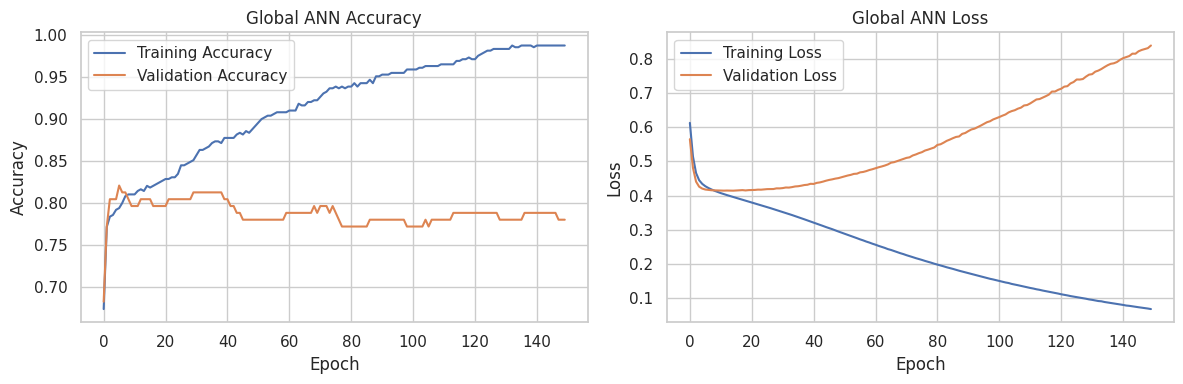

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history_A.history["accuracy"], label="Training Accuracy")
plt.plot(history_A.history["val_accuracy"], label="Validation Accuracy")

plt.title("Global ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_A.history["loss"], label="Training Loss")
plt.plot(history_A.history["val_loss"], label="Validation Loss")

plt.title("Global ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Global ANN predictions

In [ ]:
prob_A = model_A.predict(X_test_A).ravel()

pred_A = (prob_A >= 0.5).astype(int)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


Approach B: Age-Based ANN

In [ ]:
age_models = {}
age_imputers = {}
age_scalers = {}

train_age_groups = pd.cut(
    X_train["Age"],
    bins=[20, 30, 40, 50, 100],
    labels=age_groups,
    include_lowest=True
)

for group in age_groups:

    group_index = train_age_groups == group

    X_group = X_train.loc[group_index]
    y_group = y_train.loc[group_index]

    print("\nAge Group:", group)
    print("Total samples:", len(X_group))
    print("Class distribution:")
    print(y_group.value_counts())

    if len(X_group) >= 50 and y_group.value_counts().min() >= 10:

        # Fill missing values for this age group

        imputer = SimpleImputer(strategy="median")

        X_group = imputer.fit_transform(X_group)

        # Standardize this age group's features

        scaler = StandardScaler()

        X_group = scaler.fit_transform(X_group)

        # Create and train ANN

        model = create_ann()

        model.fit(
            X_group,
            y_group,
            epochs=150,
            batch_size=16,
            validation_split=0.20,
            verbose=0
        )

        age_models[group] = model
        age_imputers[group] = imputer
        age_scalers[group] = scaler

        print("Local ANN trained successfully.")

    else:

        age_models[group] = None

        print("Insufficient samples. Global ANN will be used.")

# Cell 9 — Make age-based predictions
For each test participant:
1. Identify their age group.
2. Select the corresponding ANN.
3. Apply that group's imputer and scaler.
4. Predict diabetes probability.
5. If no local model exists, use the global ANN.

In [ ]:
prob_B = np.zeros(len(X_test))

test_age_groups = pd.cut(
    X_test["Age"],
    bins=[20, 30, 40, 50, 100],
    labels=age_groups,
    include_lowest=True
)

for group in age_groups:

    group_index = (test_age_groups == group)

    if not group_index.any():
        continue

    if age_models[group] is not None:

        selected_model = age_models[group]
        selected_imputer = age_imputers[group]
        selected_scaler = age_scalers[group]

        X_group_test = X_test.loc[group_index]

        X_group_test = selected_imputer.transform(X_group_test)

        X_group_test = selected_scaler.transform(X_group_test)

        prob_B[group_index.to_numpy()] = (
            selected_model.predict(X_group_test, verbose=0).ravel()
        )

    else:

        X_group_test = X_test.loc[group_index]

        X_group_test = imputer_A.transform(X_group_test)

        X_group_test = scaler_A.transform(X_group_test)

        prob_B[group_index.to_numpy()] = (
            model_A.predict(X_group_test, verbose=0).ravel()
        )

pred_B = (prob_B >= 0.5).astype(int)

print("Age-Based ANN predictions completed.")

Compare both approaches

In [ ]:
results = pd.DataFrame({

    "Model": [
        "Global ANN",
        "Age-Based ANN"
    ],

    "Accuracy": [
        accuracy_score(y_test, pred_A),
        accuracy_score(y_test, pred_B)
    ],

    "Precision": [
        precision_score(y_test, pred_A, zero_division=0),
        precision_score(y_test, pred_B, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, pred_A, zero_division=0),
        recall_score(y_test, pred_B, zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test, pred_A, zero_division=0),
        f1_score(y_test, pred_B, zero_division=0)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, prob_A),
        roc_auc_score(y_test, prob_B)
    ]
})

display(results.round(4))

Performance visualization

In [ ]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Global ANN vs Age-Based ANN")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Confusion matrices

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(
    confusion_matrix(y_test, pred_A),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Global ANN")

sns.heatmap(
    confusion_matrix(y_test, pred_B),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Age-Based ANN")

plt.tight_layout()
plt.show()

Age-wise performance comparison

In [ ]:
test_results = X_test.copy()

test_results["Actual"] = y_test

test_results["Global_Prediction"] = pred_A
test_results["Age_Prediction"] = pred_B

test_results["Global_Probability"] = prob_A
test_results["Age_Probability"] = prob_B

test_results["Age_Group"] = test_age_groups

age_results = []

for group in age_groups:

    group_data = test_results[
        test_results["Age_Group"] == group
    ]

    if len(group_data) == 0:
        continue

    age_results.append({

        "Age Group": group,

        "Samples": len(group_data),

        "Global Accuracy": accuracy_score(
            group_data["Actual"],
            group_data["Global_Prediction"]
        ),

        "Age-Based Accuracy": accuracy_score(
            group_data["Actual"],
            group_data["Age_Prediction"]
        ),

        "Global Recall": recall_score(
            group_data["Actual"],
            group_data["Global_Prediction"],
            zero_division=0
        ),

        "Age-Based Recall": recall_score(
            group_data["Actual"],
            group_data["Age_Prediction"],
            zero_division=0
        )
    })

age_results = pd.DataFrame(age_results)

display(age_results.round(4))

Age-wise visualization

In [ ]:
age_results.set_index("Age Group")[
    ["Global Accuracy", "Age-Based Accuracy"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Age-Wise ANN Accuracy Comparison")
plt.xlabel("Age Group")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()